In [1]:
import os, glob
import numpy as np
import pandas as pd
import scanpy as sc
from pygam import LinearGAM, s
import matplotlib.pyplot as plt

In [2]:
pth = os.path.join('..', '..', '..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'cancer', 'human', 'transitions', 'SK-N-SH')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_out = os.path.join(pth, 'figures', 'cancer', 'human', 'transitions', 'SK-N-SH')

In [3]:
df = pd.read_csv(os.path.join(pth_data, 'summary.csv'), index_col = 0)
labels_dict = df.Signature.dropna().to_dict(); labels_dict

{'GSE162534': 'Gast', 'GSE229103': 'pSom', 'rRNAModifications': 'Crest'}

In [4]:
adata = sc.read_h5ad(os.path.join(pth_in, 'trajectory.h5ad'))
adata

AnnData object with n_obs × n_vars = 8442 × 27739
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'percent.RPL', 'percent.RPS', 'S.Score', 'G2M.Score', 'Phase', 'CC.Difference', 'nCount_SCT', 'nFeature_SCT', 'SCT_snn_res.0.8', 'seurat_clusters', 'myOrig.ident', 'myOrig.ident2', 'Timepoint', 'ident', 'leiden', 'celltype', 't', 'seg', 'edge', 'milestones'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'Timepoint_colors', 'X_name', 'celltype_colors', 'graph', 'leiden', 'leiden_colors', 'log1p', 'milestones_colors', 'neighbors', 'pca', 'pseudotime_list', 'seg_colors', 'umap'
    obsm: 'PCA', 'UMAP', 'X_R', 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    layers: 'logcounts'
    obsp: 'connectivities', 'distances'

In [5]:
feat_fn = sorted(glob.glob(os.path.join(pth_feat, '*.csv')))
get_src = lambda fn: os.path.split(fn)[1].replace('.csv', '')
feat_dict = {get_src(fn) : pd.read_csv(fn) for fn in feat_fn}

# module signatures
g_ref = feat_dict['union'].hsapiens.drop_duplicates()
g_ref = g_ref.loc[g_ref.isin(adata.var_names)].copy()
for src, df_src in feat_dict.items():
    if src != 'union':
        g = df_src.hsapiens.drop_duplicates()
        g = g.loc[g.isin(adata.var_names)].copy()
        sc.tl.score_genes(adata,
                          gene_list = g,
                          score_name = src,
                          ctrl_as_ref = False,
                          gene_pool = g_ref,
                          random_state = 1234)
        print(src, g.size, g_ref.size)

GSE162534 75 226
GSE229103 89 226
rRNAModifications 103 226


In [6]:
def fit_gam(Y, X, n_spl, n_pts):
    GAM = LinearGAM(s(0, n_splines = n_spl))
    GAM = GAM.fit(X, scale_01(Y))
    xx = np.linspace(X.min(), X.max(), n_pts)
    return scale_01(GAM.predict(xx))

def scale_01(Y):
    return (Y - Y.min()) / (Y.max() - Y.min())

In [7]:
# fit GAMs (signatures)
n_pts, n_spl = 500, 5
cols = list(labels_dict.keys())
X = np.zeros((len(cols), n_pts))
t = adata.obs.t.values.copy()
for i, mod in enumerate(cols):
    X[i] = fit_gam(adata.obs[mod], t, n_spl, n_pts)

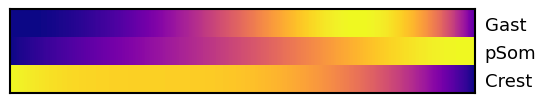

In [8]:
# plot heatmap
fig, ax = plt.subplots(1, 1, figsize = (6, 3))
ax.imshow(X, aspect = 30, interpolation = 'nearest', cmap = 'plasma')
yticks, yticklabels = np.arange(len(cols)), list(labels_dict.values())
ax.set_yticks(yticks, yticklabels, fontsize = 13)
ax.tick_params('y', left = False, labelleft = False, labelright = True)
ax.set_xticks([])
for sp in ax.spines.values(): sp.set_linewidth(1.5)
# fn = os.path.join(pth_out, f'{src}.pdf')
# plt.savefig(fn, bbox_inches = 'tight')
plt.show()

In [ ]:
# msk = (adata.obs.source != 'rRNAModifications')
# adata.obs['mesencoder'] = msk.astype(str)
# adata.write(os.path.join(pth_in, 'signatures.h5ad'))